# CS4085 Deep Learning — Lab 5
## CNN Applications with TensorFlow Keras: Smile Detection and Sign-Language Digits

**Instructor:** Dr. Naila Marir
**Course:** CS4085 Deep Learning · College of Engineering · Effat University
**Chapter:** Convolutional Neural Networks (applied lab)

---

### What you will do in this lab

1. **Part A:** Build a **binary** CNN that decides whether a person is **smiling or not**, using the Keras **Sequential API**.
2. **Part B:** Build a **multiclass** CNN that recognises **hand-sign digits 0–9**, using the Keras **Functional API**.
3. Train, evaluate, and **analyse** your models: learning curves, wrong predictions, and a confusion matrix.
4. **Challenge:** Improve the sign-digit model and compare it with the baseline.

### Learning outcomes

By the end of this lab you will be able to:

1. Build a CNN with the **Sequential API** and with the **Functional API**, and explain when to use each.
2. Choose the correct **output layer and loss** for binary vs multiclass problems.
3. Compute **output shapes and parameter counts** of CNN layers by hand.
4. Train with a **validation set**, read learning curves, and use **early stopping**.
5. Evaluate a classifier beyond accuracy (wrong predictions, confusion matrix).

## Table of Contents

0. [Why do we use a deep learning framework?](#0)
1. [Setup](#1)
2. [Part A — Smile Detector (Sequential API)](#2)
    - Exercise 1 — `happy_model`
    - Exercise 2 — Predictions and wrong cases
3. [Part B — Sign-Language Digits (Functional API)](#3)
    - Exercise 3 — `sign_model`
    - Exercise 4 — Confusion matrix
    - Exercise 5 — Challenge: improve the model
4. [Sequential vs Functional — summary](#4)
5. [Reflection questions](#5)
6. [References](#6)

<a name='0'></a>
## 0 — Why do we use a deep learning framework?

Imagine you want to build an AI system that recognises **cats and dogs** in images.

You already know how neural networks work: forward propagation, backpropagation, gradient descent, and weight updates.

**Question:** does that mean you should program every operation yourself?

Not necessarily. This short section explains why, using small code examples you can run.

### 0.1 Why did we first build networks from scratch?

In Labs 1–4 we used **Python and NumPy** to write forward propagation, the loss, backpropagation and gradient descent ourselves.

We did this to **understand what happens inside the network**. For example, one layer computes:

$$z = Wx + b \qquad a = \text{ReLU}(z)$$

Run the cell below: this is one layer written **by hand**.

In [1]:
import time
import numpy as np
import tensorflow as tf

np.random.seed(0)
x = np.random.randn(10, 1)          # 10 input features
W = np.random.randn(5, 10) * 0.1    # we create the weights ourselves
b = np.zeros((5, 1))                # we create the bias ourselves

z = W @ x + b                       # linear step
a = np.maximum(0, z)                # ReLU
print("Output of the layer (by hand):", a.ravel().round(3))

Output of the layer (by hand): [0.342 0.112 0.    0.    0.   ]


### 0.2 What is the problem with building everything from scratch?

Now imagine a **large CNN for medical image classification**, with millions of parameters and many layers. By hand, you must write convolutions, activations, gradients, parameter updates, GPU code, and more.

This creates three problems:

1. **It takes too much time.** We spend more time on basic operations than on our AI solution.
2. **It is hard to maintain.** Large hand-written code becomes complex and buggy.
3. **It can be slow.** Our code is usually slower than highly optimised libraries.

### 0.3 Andrew Ng's analogy: matrix multiplication

You know how to multiply two matrices, and you could write the loops yourself.

But if your program does **millions** of multiplications, you would use a library such as NumPy: `np.matmul(A, B)`.

Run the cell to compare our own loops with NumPy on the **same** calculation.

In [2]:
def my_matmul(A, B):
    # Matrix multiplication written by hand with three loops
    n, k = A.shape
    _, m = B.shape
    C = np.zeros((n, m))
    for i in range(n):
        for j in range(m):
            for t in range(k):
                C[i, j] += A[i, t] * B[t, j]
    return C

A = np.random.randn(100, 100)
B = np.random.randn(100, 100)

t0 = time.time(); C1 = my_matmul(A, B); t_loops = time.time() - t0
t0 = time.time(); C2 = np.matmul(A, B); t_numpy = time.time() - t0

print("Same result?      ", np.allclose(C1, C2))
print(f"Our loops:          {t_loops:.4f} s")
print(f"NumPy np.matmul:    {t_numpy:.6f} s")
print(f"NumPy is about {t_loops / max(t_numpy, 1e-9):,.0f} times faster")

Same result?       True
Our loops:          3.4581 s
NumPy np.matmul:    0.013036 s
NumPy is about 265 times faster


**Key idea:** you still *understand* matrix multiplication, but you let a library *execute* it efficiently.

Deep learning frameworks follow exactly the same principle for neural networks.

### 0.4 What is a deep learning framework?

A **deep learning framework** is a software library with ready-made tools to **build, train and deploy** neural networks. Think of it as a box of **building blocks**.

| From scratch (Labs 1–4) | With a framework (this lab) |
|---|---|
| Write the layer calculations | Use ready-made layers |
| Write the gradient calculations | **Automatic differentiation** |
| Write the update rule and training loop | Built-in **optimizers** and `fit()` |
| More manual work | Less manual work |

Examples of frameworks: **TensorFlow** (with its high-level API **Keras**), **PyTorch**, and **JAX**. In this lab we use **TensorFlow Keras**.

Run the cell: the same layer as in 0.1, but now Keras creates the weights for us.

In [3]:
layer = tf.keras.layers.Dense(5, activation="relu")   # 5 neurons, ReLU
out = layer(tf.random.normal((1, 10)))                 # 1 example with 10 features

print("Weights created automatically:", layer.kernel.shape)   # (10, 5)
print("Biases created automatically: ", layer.bias.shape)     # (5,)
print("Output shape:", out.shape)

Weights created automatically: (10, 5)
Biases created automatically:  (5,)
Output shape: (1, 5)


**The mathematics has not disappeared — the framework does it for us.** This includes the gradients.

For $y = w^2 + 3w$ we know by hand that $\frac{dy}{dw} = 2w + 3$. At $w = 2$ this is $7$. Let TensorFlow compute it automatically:

In [4]:
w = tf.Variable(2.0)
with tf.GradientTape() as tape:      # "record" the computation
    y = w**2 + 3*w
grad = tape.gradient(y, w)           # automatic differentiation

print("Gradient by hand:      ", 2*2.0 + 3)
print("Gradient by TensorFlow:", grad.numpy())

Gradient by hand:       7.0
Gradient by TensorFlow: 7.0


This is exactly what `fit()` does for you in every training step: it computes **all** the gradients of the loss and updates **all** the weights — no backpropagation code needed.

### 0.5 How do we choose a framework?

Andrew Ng suggests three criteria instead of simply asking "which one is most popular?":

1. **Ease of programming** — both for **developing** models (try model A, change it, train model B) and for **deploying** them to real users (for example, a hospital app).
2. **Running speed** — can it train and run my model efficiently on **my hardware** (GPUs, memory)? Speed depends on hardware, model and workload.
3. **Is it truly open?** — *open source* (code you can inspect, modify and share) **and** *good governance* (who makes decisions, and will it stay open and supported in the future?).

There is no single best framework. It depends on the application:

| Application | What matters most |
|---|---|
| Academic research | Flexibility and experimentation |
| Large-scale training | GPU efficiency, distributed training |
| Mobile AI app | Deployment support, model optimisation |
| Enterprise AI system | Maintenance, reliability, integration |
| New experimental architecture | Customisation, automatic differentiation |

### 0.6 What does "higher level of abstraction" mean?

**Abstraction** means hiding details so we can focus on the main task:

1. **Python loops** → we write every multiplication.
2. **NumPy** → we stop writing matrix multiplication.
3. **TensorFlow / PyTorch** → we stop writing gradients and GPU code.
4. **Keras** → we describe the network as a list of layers.

At the top level we only think about questions like: *which architecture? how many layers? which loss? how do we train and evaluate?*

Example: a network that takes **10 features** and predicts **one of 3 classes**, in Keras:

In [5]:
model = tf.keras.Sequential([
    tf.keras.Input(shape=(10,)),
    tf.keras.layers.Dense(16, activation="relu"),   # 10 inputs -> 16 hidden neurons
    tf.keras.layers.Dense(3, activation="softmax")  # 16 hidden -> 3 class probabilities
])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_1 (Dense)                 │ (None, 16)             │           176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 227 (908.00 B)

 Trainable params: 227 (908.00 B)

 Non-trainable params: 0 (0.00 B)

For comparison, the same network in **PyTorch** looks almost identical:

```python
import torch.nn as nn
model = nn.Sequential(nn.Linear(10, 16), nn.ReLU(), nn.Linear(16, 3))
```

In a few lines we defined a full network. We did **not** write weight matrices, individual neurons or gradients. We still choose the data, loss, optimizer and training procedure.

### 0.7 The most important takeaway

How we learn and practise deep learning:

1. **Understand the mathematics** — neurons, gradients, networks.
2. **Implement from scratch** — Python and NumPy (Labs 1–4).
3. **Use a framework** — build complex models efficiently (**this lab**).
4. **Solve real problems** — experiment, improve, deploy.

> **First learn how deep learning works. Then use frameworks so you do not rebuild everything yourself.**
> Frameworks do not replace your understanding — they let you apply it to bigger, real problems.

Now let's use TensorFlow Keras to build two real CNN applications.

<a name='1'></a>
## 1 — Setup

### 1.1 Download the datasets

You need **two datasets**. Download them once to your computer; in the next step you upload them to Google Drive.

| Dataset | Link | Files you need |
|---|---|---|
| Happy House (smiling faces) | https://www.kaggle.com/datasets/iarunava/happy-house-dataset | `train_happy.h5`, `test_happy.h5` |
| Sign Language Digits | https://github.com/ardamavi/Sign-Language-Digits-Dataset (green **Code** button → **Download ZIP**) | the `Dataset/` folder with sub-folders `0` … `9` |

### 1.2 Put the datasets in your Google Drive

We run this lab in **Google Colab** and keep the data in **Google Drive**.

1. Unzip the Sign Language Digits ZIP on your computer. Inside it, find the folder **`Dataset`** (it contains the sub-folders `0` to `9`).
2. In Google Drive, create the folder **`MyDrive/ML_Labs/Lab5/`**.
3. Upload into `Lab5/`:
    - the two files `train_happy.h5` and `test_happy.h5`,
    - the whole **`Dataset`** folder (with its 10 sub-folders).

Your Drive should look like this:

```
MyDrive/
└── ML_Labs/
    └── Lab5/
        ├── train_happy.h5
        ├── test_happy.h5
        └── Dataset/
            ├── 0/   (images of sign 0)
            ├── 1/
            ├── ...
            └── 9/
```

> **Tip:** upload the folder with Drive's **New → Folder upload**. It can take a few minutes because there are about 2,000 small images.

### 1.3 Connect Colab to your Google Drive

Run the cell below. Colab will ask you to sign in and **allow access to your Drive**. After that, your Drive appears at `/content/drive/MyDrive`.

(If you run the notebook on your own computer instead of Colab, the cell skips this step and looks for a local `Lab5/` folder next to the notebook.)

In [6]:
try:
    from google.colab import drive
    drive.mount("/content/drive")
    DATA_DIR = "/content/drive/MyDrive/ML_Labs/Lab5"   # change if your Lab5 folder is elsewhere
    print("Running in Colab - Google Drive mounted.")
except ImportError:
    DATA_DIR = "Lab5"
    print("Not running in Colab - using the local 'Lab5' folder.")

Mounted at /content/drive
Running in Colab - Google Drive mounted.


### 1.4 Import the libraries

We only need four libraries: **NumPy**, **h5py** (to read `.h5` files), **Matplotlib** (plots) and **TensorFlow/Keras**.

In [7]:
import os
import numpy as np
import h5py
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers as tfl

# Reproducibility
np.random.seed(1)
tf.random.set_seed(1)

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


In [8]:
# ---- Paths inside DATA_DIR (set in 1.3). Change only if your folders are named differently ----
HAPPY_TRAIN = os.path.join(DATA_DIR, "train_happy.h5")
HAPPY_TEST  = os.path.join(DATA_DIR, "test_happy.h5")
SIGNS_DIR   = os.path.join(DATA_DIR, "Dataset")   # contains the folders 0 ... 9

for path in [HAPPY_TRAIN, HAPPY_TEST, SIGNS_DIR]:
    status = "OK" if os.path.exists(path) else "MISSING  <-- check section 1.2"
    print(f"{path:85s} {status}")

/content/drive/MyDrive/ML_Labs/Lab5/train_happy.h5                                    OK
/content/drive/MyDrive/ML_Labs/Lab5/test_happy.h5                                     OK
/content/drive/MyDrive/ML_Labs/Lab5/Dataset                                           OK


### 1.5 Helper functions (given)

These two helpers are used in both parts. Read them, but you do not need to change them.

- `check_model(model, expected)` compares your model, layer by layer, with the expected **layer type**, **output shape** and **number of parameters**.
- `plot_history(history)` draws the training and validation **loss** and **accuracy** curves.

In [9]:
def check_model(model, expected):
    # Compare a model with a list of (layer_type, output_shape, n_params).
    rows = [(l.__class__.__name__, tuple(l.output.shape), l.count_params())
            for l in model.layers if l.__class__.__name__ != "InputLayer"]
    ok = len(rows) == len(expected)
    for i, exp in enumerate(expected):
        got = rows[i] if i < len(rows) else ("<missing>", None, None)
        match = got == exp
        ok = ok and match
        print(f"{'OK ' if match else 'XX '} expected {exp}   got {got}")
    print("\nAll layers match!" if ok else "\nSome layers do not match - review your model.")


def plot_history(history, title=""):
    h = history.history
    epochs = range(1, len(h["loss"]) + 1)
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(epochs, h["loss"], label="train")
    ax[0].plot(epochs, h["val_loss"], label="validation")
    ax[0].set(title=f"{title} loss", xlabel="epoch", ylabel="loss"); ax[0].legend()
    ax[1].plot(epochs, h["accuracy"], label="train")
    ax[1].plot(epochs, h["val_accuracy"], label="validation")
    ax[1].set(title=f"{title} accuracy", xlabel="epoch", ylabel="accuracy"); ax[1].legend()
    plt.show()

<a name='2'></a>
## 2 — Part A: Smile Detector (binary classification, Sequential API)

**Problem.** The *Happy House* only lets people in if they are **smiling**. Given a 64×64 colour photo of a face, predict:

- `1` → smiling
- `0` → not smiling

### 2.1 Load the data

The `.h5` files store the images and labels as arrays. The function below opens them with `h5py`.

In [10]:
def load_happy_data(train_path=HAPPY_TRAIN, test_path=HAPPY_TEST):
    with h5py.File(train_path, "r") as f:
        X_train = np.array(f["train_set_x"][:])
        y_train = np.array(f["train_set_y"][:])
    with h5py.File(test_path, "r") as f:
        X_test = np.array(f["test_set_x"][:])
        y_test = np.array(f["test_set_y"][:])
    # labels as column vectors of shape (m, 1)
    return X_train, y_train.reshape(-1, 1), X_test, y_test.reshape(-1, 1)

X_train_orig, y_train, X_test_orig, y_test = load_happy_data()

print("X_train shape:", X_train_orig.shape, "| y_train shape:", y_train.shape)
print("X_test  shape:", X_test_orig.shape,  "| y_test  shape:", y_test.shape)
print("Smiling in train:", int(y_train.sum()), "of", len(y_train))

X_train shape: (600, 64, 64, 3) | y_train shape: (600, 1)
X_test  shape: (150, 64, 64, 3) | y_test  shape: (150, 1)
Smiling in train: 300 of 600


### 2.2 Look at the data

Always look at your data before building a model.

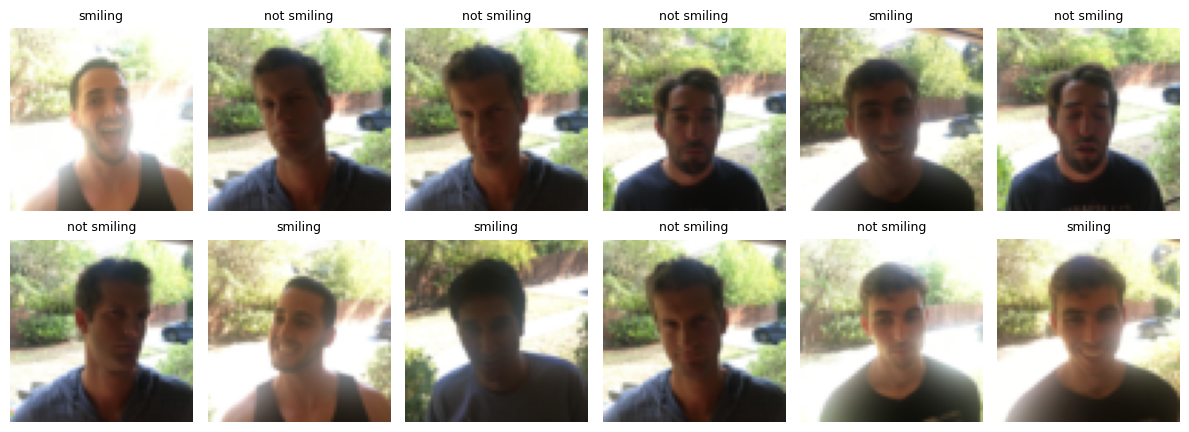

In [11]:
fig, axes = plt.subplots(2, 6, figsize=(12, 4.5))
for ax, i in zip(axes.ravel(), np.random.choice(len(X_train_orig), 12, replace=False)):
    ax.imshow(X_train_orig[i])
    ax.set_title("smiling" if y_train[i, 0] == 1 else "not smiling", fontsize=9)
    ax.axis("off")
plt.tight_layout(); plt.show()

### 2.3 Normalise the images

Pixel values are integers from 0 to 255. Neural networks train better with small inputs, so we divide by 255 to get values in **[0, 1]**.

In [12]:
X_train = X_train_orig / 255.0
X_test  = X_test_orig / 255.0
print("min:", X_train.min(), "max:", X_train.max())

min: 0.00392156862745098 max: 1.0


### 2.4 The Sequential API

A **Sequential** model is a **list of layers**: the output of each layer is the input of the next one. Use it when the model is a **straight line** — one input, one output, no branches.

```python
model = tf.keras.Sequential([
    tfl.Input(shape=(64, 64, 3)),   # tells Keras the input size
    tfl.SomeLayer(...),
    tfl.AnotherLayer(...),
])
```

<a name='ex-1'></a>
### Exercise 1 — `happy_model`

Build this model:

`INPUT → ZEROPAD2D → CONV2D → BATCHNORM → RELU → MAXPOOL → FLATTEN → DENSE`

| Layer | Keras call | Settings |
|---|---|---|
| Input | `tfl.Input` | shape `(64, 64, 3)` |
| Zero padding | `tfl.ZeroPadding2D` | padding `3` |
| Convolution | `tfl.Conv2D` | `32` filters, kernel `7×7`, stride `1` |
| Batch normalisation | `tfl.BatchNormalization` | `axis=3` (the channels axis) |
| Activation | `tfl.ReLU` | — |
| Max pooling | `tfl.MaxPool2D` | default (2×2, stride 2) |
| Flatten | `tfl.Flatten` | — |
| Output | `tfl.Dense` | `1` unit, `activation='sigmoid'` |

**Before you code, predict the shapes:** padding 3 turns 64×64 into **70×70**. A 7×7 filter with stride 1 gives (70 − 7)/1 + 1 = **64**. Pooling halves it to **32×32**.

In [16]:
def happy_model():
    model = tf.keras.Sequential([
        tfl.Input(shape=(64, 64, 3)),
        # YOUR CODE STARTS HERE (7 layers)
        tfl.ZeroPadding2D(padding=3),
        tfl.Conv2D(32, kernel_size=7, strides=1),
        tfl.BatchNormalization(axis=3),
        tfl.ReLU(),
        tfl.MaxPool2D(),
        tfl.Flatten(),
        tfl.Dense(1, activation='sigmoid')
        # YOUR CODE ENDS HERE
    ])
    return model

In [17]:
model_a = happy_model()

expected_a = [
    ("ZeroPadding2D",      (None, 70, 70, 3),  0),
    ("Conv2D",             (None, 64, 64, 32), 4736),
    ("BatchNormalization", (None, 64, 64, 32), 128),
    ("ReLU",               (None, 64, 64, 32), 0),
    ("MaxPooling2D",       (None, 32, 32, 32), 0),
    ("Flatten",            (None, 32768),      0),
    ("Dense",              (None, 1),          32769),
]
check_model(model_a, expected_a)

OK  expected ('ZeroPadding2D', (None, 70, 70, 3), 0)   got ('ZeroPadding2D', (None, 70, 70, 3), 0)
OK  expected ('Conv2D', (None, 64, 64, 32), 4736)   got ('Conv2D', (None, 64, 64, 32), 4736)
OK  expected ('BatchNormalization', (None, 64, 64, 32), 128)   got ('BatchNormalization', (None, 64, 64, 32), 128)
OK  expected ('ReLU', (None, 64, 64, 32), 0)   got ('ReLU', (None, 64, 64, 32), 0)
OK  expected ('MaxPooling2D', (None, 32, 32, 32), 0)   got ('MaxPooling2D', (None, 32, 32, 32), 0)
OK  expected ('Flatten', (None, 32768), 0)   got ('Flatten', (None, 32768), 0)
OK  expected ('Dense', (None, 1), 32769)   got ('Dense', (None, 1), 32769)

All layers match!


**Check your understanding — where do the parameter counts come from?**

- **Conv2D:** each filter has 7 × 7 × 3 weights + 1 bias = 148. With 32 filters: 148 × 32 = **4,736**.
- **BatchNorm:** 4 values per channel (γ, β, moving mean, moving variance): 4 × 32 = **128**.
- **Dense:** 32 × 32 × 32 = 32,768 inputs, plus 1 bias = **32,769**.

Notice that the **Dense layer has ~7× more parameters than the convolution**. This is why CNNs usually shrink the image (pooling) before flattening.

### 2.5 Compile and train

For a **binary** problem we use:

- a **sigmoid** output (one number between 0 and 1),
- the **binary cross-entropy** loss.

We keep **10% of the training images for validation**, so we can watch for overfitting while training.

In [18]:
model_a.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
model_a.summary()

history_a = model_a.fit(X_train, y_train,
                        epochs=10, batch_size=16,
                        validation_split=0.1, verbose=2)

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ zero_padding2d (ZeroPadding2D)  │ (None, 70, 70, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 64, 64, 32)     │         4,736 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │        32,769 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 37,633 (147.00 KB)

 Trainable params: 37,569 (146.75 KB)

 Non-trainable params: 64 (256.00 B)

Epoch 1/10
34/34 - 5s - 148ms/step - accuracy: 0.7352 - loss: 0.8288 - val_accuracy: 0.8000 - val_loss: 0.4598
Epoch 2/10
34/34 - 5s - 160ms/step - accuracy: 0.9370 - loss: 0.1623 - val_accuracy: 0.7667 - val_loss: 0.4382
Epoch 3/10
34/34 - 4s - 111ms/step - accuracy: 0.9519 - loss: 0.1236 - val_accuracy: 0.8667 - val_loss: 0.3414
Epoch 4/10
34/34 - 5s - 140ms/step - accuracy: 0.9630 - loss: 0.1214 - val_accuracy: 0.9500 - val_loss: 0.2569
Epoch 5/10
34/34 - 4s - 129ms/step - accuracy: 0.9685 - loss: 0.0826 - val_accuracy: 0.9333 - val_loss: 0.2398
Epoch 6/10
34/34 - 5s - 145ms/step - accuracy: 0.9611 - loss: 0.0976 - val_accuracy: 0.9833 - val_loss: 0.2386
Epoch 7/10
34/34 - 3s - 101ms/step - accuracy: 0.9796 - loss: 0.0710 - val_accuracy: 0.9333 - val_loss: 0.1621
Epoch 8/10
34/34 - 3s - 102ms/step - accuracy: 0.9667 - loss: 0.0977 - val_accuracy: 0.8000 - val_loss: 0.3470
Epoch 9/10
34/34 - 5s - 159ms/step - accuracy: 0.9722 - loss: 0.0828 - val_accuracy: 0.7333 - val_loss: 0.4645
E

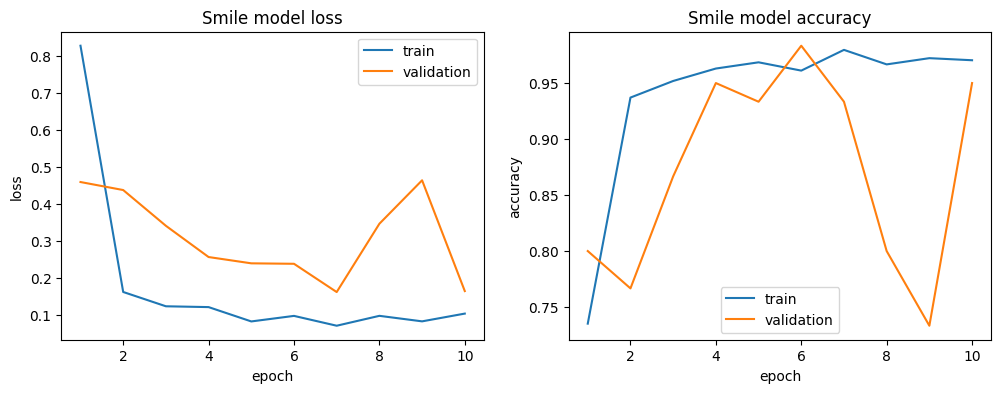

Test accuracy: 0.887


In [19]:
plot_history(history_a, "Smile model")

test_loss, test_acc = model_a.evaluate(X_test, y_test, verbose=0)
print(f"Test accuracy: {test_acc:.3f}")

<a name='ex-2'></a>
### Exercise 2 — Predictions and wrong cases

The model outputs a **probability** of smiling. To get a class we apply a **threshold of 0.5**.

1. Use `model_a.predict(X_test)` to get the probabilities.
2. Convert them to 0/1 predictions with the threshold.
3. Find the indices of the **wrong** predictions.

In [22]:
# YOUR CODE STARTS HERE
probs  = model_a.predict(X_test)
y_pred = (probs > 0.5).astype(int)
wrong  = np.where(y_pred != y_test)[0]
# YOUR CODE ENDS HERE

print("Number of wrong predictions:", len(wrong), "out of", len(y_test))

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step
Number of wrong predictions: 17 out of 150


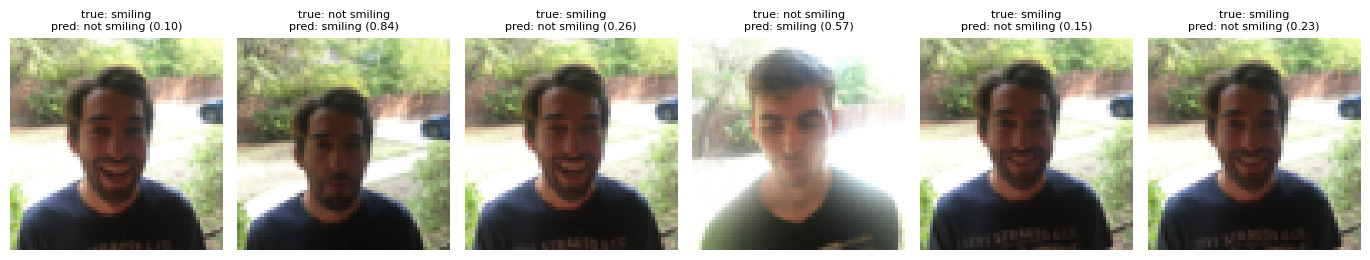

In [23]:
# Show up to 6 wrong predictions with the model's confidence
names = {0: "not smiling", 1: "smiling"}
n = min(6, len(wrong))
if n == 0:
    print("No mistakes on the test set!")
else:
    fig, axes = plt.subplots(1, n, figsize=(2.3 * n, 3), squeeze=False)
    for ax, i in zip(axes[0], wrong[:n]):
        ax.imshow(X_test_orig[i]); ax.axis("off")
        ax.set_title(f"true: {names[y_test[i,0]]}\npred: {names[y_pred[i,0]]} ({probs[i,0]:.2f})", fontsize=8)
    plt.tight_layout(); plt.show()

**Discuss:** look at the wrong cases. Are they hard for a human too (closed-mouth smiles, unusual lighting, head turned)? What does that tell you about the data?


the cases are easy for humans to recognize, the data is clear enough. This tells us the model's mistakes come from its poor learning rather than unreadable data

<a name='3'></a>
## 3 — Part B: Sign-Language Digits (multiclass classification, Functional API)

**Problem.** Given a photo of a hand showing a digit in sign language, predict the digit **0–9** (10 classes).

The dataset was collected by 218 students at Ayrancı Anadolu High School (Ankara). Each image is 100×100 RGB; we resize them to **64×64** when loading.

### 3.1 Load the data directly from the folders

Each class is a folder (`0`, `1`, …, `9`) inside `Lab5/Dataset/` in your Drive. Keras can read this structure directly with `image_dataset_from_directory`:

- `validation_split=0.2` keeps **20%** of the images for validation,
- `label_mode="categorical"` gives **one-hot labels**, e.g. digit 3 → `[0,0,0,1,0,0,0,0,0,0]`.

In [24]:
IMG_SIZE = (64, 64)
BATCH = 32

train_ds, val_ds = tf.keras.utils.image_dataset_from_directory(
    SIGNS_DIR,
    validation_split=0.2, subset="both", seed=1,
    image_size=IMG_SIZE, batch_size=BATCH,
    label_mode="categorical")

class_names = train_ds.class_names
NUM_CLASSES = len(class_names)
print("Classes:", class_names)

Found 563 files belonging to 10 classes.
Using 451 files for training.
Using 112 files for validation.
Classes: ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9']


Batch of images: (32, 64, 64, 3) | batch of labels: (32, 10)


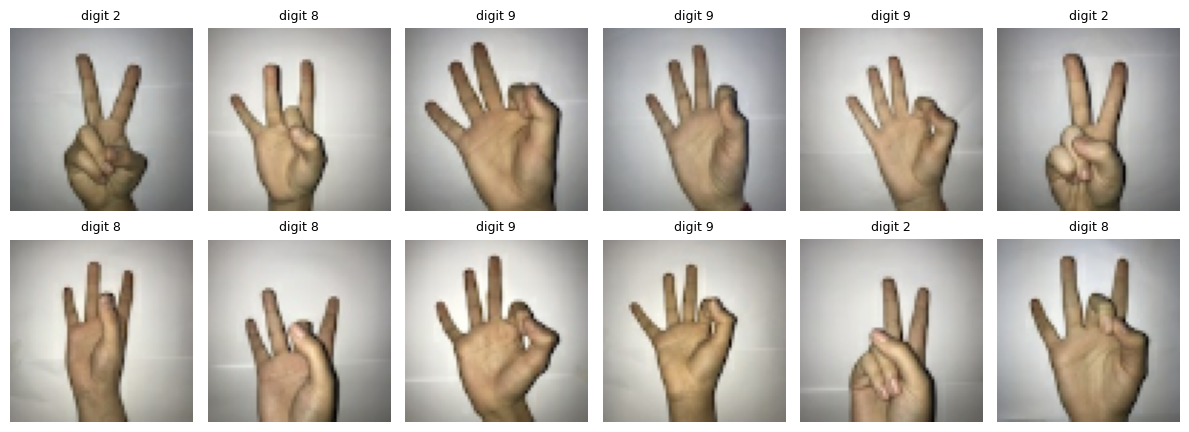

In [25]:
images, labels = next(iter(train_ds))
print("Batch of images:", images.shape, "| batch of labels:", labels.shape)

plt.figure(figsize=(12, 4.5))
for i in range(12):
    plt.subplot(2, 6, i + 1)
    plt.imshow(images[i].numpy().astype("uint8"))
    plt.title(f"digit {class_names[np.argmax(labels[i])]}", fontsize=9)
    plt.axis("off")
plt.tight_layout(); plt.show()

In [26]:
# Keep the data in memory and prepare the next batch while the current one trains
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().shuffle(1000, seed=1).prefetch(AUTOTUNE)
val_ds   = val_ds.cache().prefetch(AUTOTUNE)

### 3.2 The Functional API

In the **Functional API** you treat every layer as a **function** and call it on a tensor:

```python
inputs = tf.keras.Input(shape=(64, 64, 3))
x = tfl.Conv2D(8, 4, padding="same")(inputs)   # layer(...)(input)
x = tfl.ReLU()(x)
...
outputs = tfl.Dense(10, activation="softmax")(x)
model = tf.keras.Model(inputs=inputs, outputs=outputs)
```

The model is a **graph** of layers. Our model today is still a straight line, but the same style lets you build **branches, skip connections and multiple inputs/outputs** (for example ResNets, in the next lab).

**New idea — normalise inside the model.** Instead of dividing by 255 in NumPy, we add a `tfl.Rescaling(1./255)` layer. The model then accepts **raw images** at prediction time.

<a name='ex-3'></a>
### Exercise 3 — `sign_model`

Build this model with the Functional API:

`INPUT → RESCALING → CONV2D → RELU → MAXPOOL → CONV2D → RELU → MAXPOOL → FLATTEN → DENSE`

| Variable | Layer | Settings |
|---|---|---|
| `x0` | `tfl.Rescaling` | `1./255` |
| `Z1` | `tfl.Conv2D` | `8` filters, `4×4`, stride 1, `padding='same'` |
| `A1` | `tfl.ReLU` | — |
| `P1` | `tfl.MaxPool2D` | pool `8×8`, stride `8`, `padding='same'` |
| `Z2` | `tfl.Conv2D` | `16` filters, `2×2`, stride 1, `padding='same'` |
| `A2` | `tfl.ReLU` | — |
| `P2` | `tfl.MaxPool2D` | pool `4×4`, stride `4`, `padding='same'` |
| `F`  | `tfl.Flatten` | — |
| `outputs` | `tfl.Dense` | `num_classes` units, `activation='softmax'` |

In [27]:
def sign_model(input_shape=(64, 64, 3), num_classes=10):
    inputs = tf.keras.Input(shape=input_shape)
    # YOUR CODE STARTS HERE
    x0 = tfl.Rescaling(1./255)(inputs)
    Z1 = tfl.Conv2D(8, 4, padding='same')(x0)
    A1 = tfl.ReLU()(Z1)
    P1 = tfl.MaxPool2D(pool_size=8, strides=8, padding='same')(A1)
    Z2 = tfl.Conv2D(16, 2, padding='same')(P1)
    A2 = tfl.ReLU()(Z2)
    P2 = tfl.MaxPool2D(pool_size=4, strides=4, padding='same')(A2)
    F  = tfl.Flatten()(P2)
    outputs = tfl.Dense(num_classes, activation='softmax')(F)
    # YOUR CODE ENDS HERE
    return tf.keras.Model(inputs=inputs, outputs=outputs)

In [28]:
model_b = sign_model(num_classes=NUM_CLASSES)

expected_b = [
    ("Rescaling",    (None, 64, 64, 3),  0),
    ("Conv2D",       (None, 64, 64, 8),  392),
    ("ReLU",         (None, 64, 64, 8),  0),
    ("MaxPooling2D", (None, 8, 8, 8),    0),
    ("Conv2D",       (None, 8, 8, 16),   528),
    ("ReLU",         (None, 8, 8, 16),   0),
    ("MaxPooling2D", (None, 2, 2, 16),   0),
    ("Flatten",      (None, 64),         0),
    ("Dense",        (None, 10),         650),
]
check_model(model_b, expected_b)

OK  expected ('Rescaling', (None, 64, 64, 3), 0)   got ('Rescaling', (None, 64, 64, 3), 0)
OK  expected ('Conv2D', (None, 64, 64, 8), 392)   got ('Conv2D', (None, 64, 64, 8), 392)
OK  expected ('ReLU', (None, 64, 64, 8), 0)   got ('ReLU', (None, 64, 64, 8), 0)
OK  expected ('MaxPooling2D', (None, 8, 8, 8), 0)   got ('MaxPooling2D', (None, 8, 8, 8), 0)
OK  expected ('Conv2D', (None, 8, 8, 16), 528)   got ('Conv2D', (None, 8, 8, 16), 528)
OK  expected ('ReLU', (None, 8, 8, 16), 0)   got ('ReLU', (None, 8, 8, 16), 0)
OK  expected ('MaxPooling2D', (None, 2, 2, 16), 0)   got ('MaxPooling2D', (None, 2, 2, 16), 0)
OK  expected ('Flatten', (None, 64), 0)   got ('Flatten', (None, 64), 0)
OK  expected ('Dense', (None, 10), 650)   got ('Dense', (None, 10), 650)

All layers match!


**Check your understanding.**

- `padding='same'` with stride 1 keeps the size: 64×64 stays 64×64.
- An 8×8 pool with stride 8 divides the size by 8: 64 → **8**. A 4×4 pool with stride 4: 8 → **2**.
- Conv2D #1: (4·4·3 + 1) · 8 = **392**. Conv2D #2: (2·2·8 + 1) · 16 = **528**. Dense: (64 + 1) · 10 = **650**.
- This model has only about **1,600 parameters** — compare that with the 37,000 of the smile model.

### 3.3 Compile and train with early stopping

For a **multiclass** problem we use:

- a **softmax** output (10 probabilities that sum to 1),
- the **categorical cross-entropy** loss (because the labels are one-hot).

**Early stopping** watches the validation loss and stops training when it stops improving for `patience` epochs, then restores the best weights. This saves time and reduces overfitting.

In [29]:
model_b.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])

early_stop = tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=10,
                                              restore_best_weights=True)

history_b = model_b.fit(train_ds, validation_data=val_ds,
                        epochs=100, callbacks=[early_stop], verbose=2)

Epoch 1/100
15/15 - 54s - 4s/step - accuracy: 0.3282 - loss: 2.0774 - val_accuracy: 0.2946 - val_loss: 1.7955
Epoch 2/100
15/15 - 1s - 49ms/step - accuracy: 0.3592 - loss: 1.5923 - val_accuracy: 0.3393 - val_loss: 1.3371
Epoch 3/100
15/15 - 1s - 84ms/step - accuracy: 0.3836 - loss: 1.2309 - val_accuracy: 0.5000 - val_loss: 1.1232
Epoch 4/100
15/15 - 1s - 83ms/step - accuracy: 0.4634 - loss: 1.1377 - val_accuracy: 0.4375 - val_loss: 1.0952
Epoch 5/100
15/15 - 1s - 49ms/step - accuracy: 0.5055 - loss: 1.1105 - val_accuracy: 0.4554 - val_loss: 1.0787
Epoch 6/100
15/15 - 2s - 104ms/step - accuracy: 0.4989 - loss: 1.1099 - val_accuracy: 0.4464 - val_loss: 1.0744
Epoch 7/100
15/15 - 2s - 104ms/step - accuracy: 0.5055 - loss: 1.0873 - val_accuracy: 0.3482 - val_loss: 1.0813
Epoch 8/100
15/15 - 2s - 146ms/step - accuracy: 0.5233 - loss: 1.0731 - val_accuracy: 0.5446 - val_loss: 1.0427
Epoch 9/100
15/15 - 1s - 48ms/step - accuracy: 0.6098 - loss: 1.0540 - val_accuracy: 0.5804 - val_loss: 1.0380

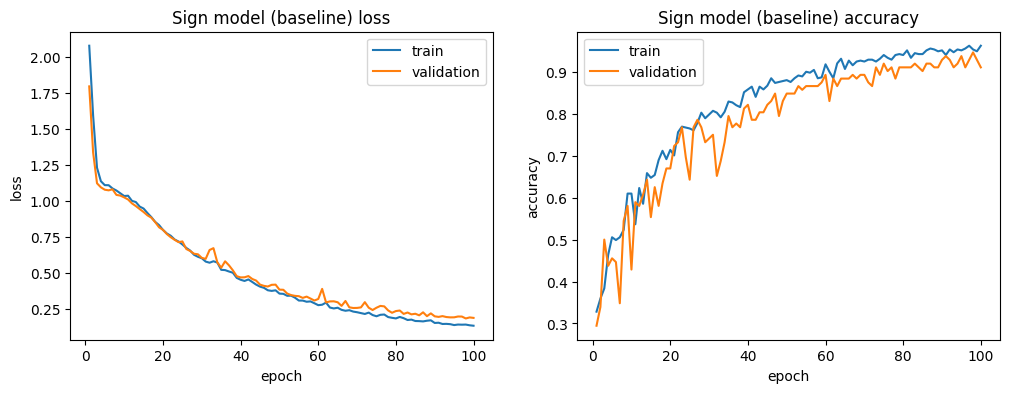

Stopped after 100 epochs | validation accuracy: 0.946


In [30]:
plot_history(history_b, "Sign model (baseline)")
val_loss_b, val_acc_b = model_b.evaluate(val_ds, verbose=0)
print(f"Stopped after {len(history_b.history['loss'])} epochs | validation accuracy: {val_acc_b:.3f}")

<a name='ex-4'></a>
### Exercise 4 — Confusion matrix

Accuracy is a single number. A **confusion matrix** shows **which digits are confused with which**: row = true digit, column = predicted digit.

Complete the loop:

1. Get the predicted probabilities for the batch with `model_b.predict_on_batch(x)`.
2. Convert the one-hot labels **and** the probabilities to digit indices with `np.argmax(..., axis=1)`.

In [32]:
y_true_all, y_pred_all = [], []
for x, y in val_ds:
    # YOUR CODE STARTS HERE
    probs_batch = model_b.predict_on_batch(x)
    y_true_all.extend(np.argmax(y, axis=1))
    y_pred_all.extend(np.argmax(probs_batch, axis=1))
    # YOUR CODE ENDS HERE

cm = tf.math.confusion_matrix(y_true_all, y_pred_all, num_classes=NUM_CLASSES).numpy()
print(cm)

[[ 0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0  0  0]
 [ 0  0 39  0  0  0  0  0  1  0]
 [ 0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0  0  0]
 [ 0  0  2  0  0  0  0  0 30  2]
 [ 0  0  1  0  0  0  0  0  0 37]]


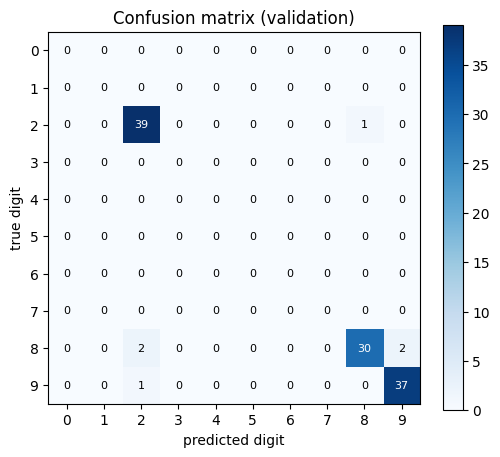

digit 0: nan
digit 1: nan
digit 2: 0.97
digit 3: nan
digit 4: nan
digit 5: nan
digit 6: nan
digit 7: nan
digit 8: 0.88
digit 9: 0.97


/tmp/ipykernel_594/309160614.py:12: RuntimeWarning: invalid value encountered in divide
  per_class = cm.diagonal() / cm.sum(axis=1)


In [33]:
plt.figure(figsize=(6, 5))
plt.imshow(cm, cmap="Blues")
plt.colorbar()
plt.xticks(range(NUM_CLASSES), class_names); plt.yticks(range(NUM_CLASSES), class_names)
plt.xlabel("predicted digit"); plt.ylabel("true digit"); plt.title("Confusion matrix (validation)")
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        plt.text(j, i, cm[i, j], ha="center", va="center",
                 color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=8)
plt.show()

per_class = cm.diagonal() / cm.sum(axis=1)
for d, acc in zip(class_names, per_class):
    print(f"digit {d}: {acc:.2f}")

**Discuss:** which two digits are confused most often? Look at the example images in 3.1 — do those hand shapes look similar?

> Digit 8 is confused most often because its hand shape looks very similar to other digits.



<a name='ex-5'></a>
### Exercise 5 — Challenge: improve the model

The baseline is very small. Build `better_sign_model` with the Functional API and try to **beat the baseline validation accuracy**. Suggested design (you may change it):

`INPUT → RESCALING → [CONV2D(32, 3×3, same) → RELU → MAXPOOL(2×2)] → [CONV2D(64, 3×3, same) → RELU → MAXPOOL(2×2)] → FLATTEN → DROPOUT(0.3) → DENSE(10, softmax)`

Ideas to explore:

- **Smaller pooling windows** keep more spatial detail.
- **More filters** let the network learn more patterns.
- **Dropout** (from Lab 4) reduces overfitting.

In [34]:
def better_sign_model(input_shape=(64, 64, 3), num_classes=10):
    inputs = tf.keras.Input(shape=input_shape)
    # YOUR CODE STARTS HERE
    x = tfl.Rescaling(1./255)(inputs)

    x = tfl.Conv2D(32, (3, 3), padding='same')(x)
    x = tfl.ReLU()(x)
    x = tfl.MaxPool2D(pool_size=(2, 2))(x)

    x = tfl.Conv2D(64, (3, 3), padding='same')(x)
    x = tfl.ReLU()(x)
    x = tfl.MaxPool2D(pool_size=(2, 2))(x)

    x = tfl.Flatten()(x)
    x = tfl.Dropout(0.3)(x)
    outputs = tfl.Dense(num_classes, activation='softmax')(x)
    # YOUR CODE ENDS HERE
    return tf.keras.Model(inputs=inputs, outputs=outputs)

Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 64, 64, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_3 (ReLU)                  │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_4 (ReLU)                  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 16384)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16384)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │       163,850 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 183,242 (715.79 KB)

 Trainable params: 183,242 (715.79 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
15/15 - 10s - 648ms/step - accuracy: 0.3858 - loss: 1.2479 - val_accuracy: 0.3304 - val_loss: 0.9983
Epoch 2/100
15/15 - 6s - 375ms/step - accuracy: 0.6785 - loss: 0.8730 - val_accuracy: 0.8214 - val_loss: 0.6209
Epoch 3/100
15/15 - 3s - 224ms/step - accuracy: 0.8293 - loss: 0.5387 - val_accuracy: 0.8839 - val_loss: 0.3700
Epoch 4/100
15/15 - 6s - 386ms/step - accuracy: 0.8980 - loss: 0.3171 - val_accuracy: 0.9018 - val_loss: 0.2529
Epoch 5/100
15/15 - 3s - 197ms/step - accuracy: 0.9024 - loss: 0.2392 - val_accuracy: 0.9196 - val_loss: 0.2061
Epoch 6/100
15/15 - 2s - 159ms/step - accuracy: 0.9401 - loss: 0.1644 - val_accuracy: 0.9554 - val_loss: 0.1672
Epoch 7/100
15/15 - 2s - 157ms/step - accuracy: 0.9446 - loss: 0.1609 - val_accuracy: 0.9464 - val_loss: 0.1749
Epoch 8/100
15/15 - 2s - 160ms/step - accuracy: 0.9557 - loss: 0.1235 - val_accuracy: 0.9554 - val_loss: 0.1640
Epoch 9/100
15/15 - 4s - 234ms/step - accuracy: 0.9512 - loss: 0.1214 - val_accuracy: 0.9554 - val_loss

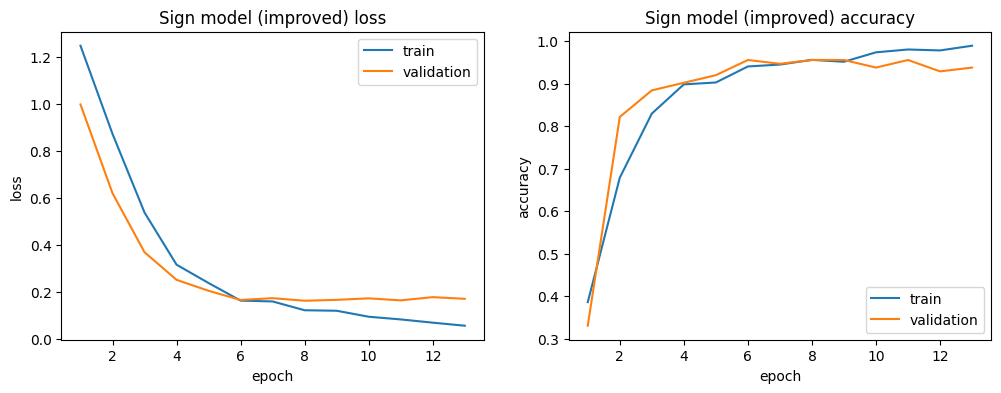

In [35]:
model_c = better_sign_model(num_classes=NUM_CLASSES)
model_c.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])
model_c.summary()

history_c = model_c.fit(train_ds, validation_data=val_ds, epochs=100,
                        callbacks=[tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=5,
                                                                    restore_best_weights=True)],
                        verbose=2)
plot_history(history_c, "Sign model (improved)")

In [36]:
_, val_acc_c = model_c.evaluate(val_ds, verbose=0)
print(f"{'Model':<12}{'Parameters':>12}{'Val. accuracy':>16}")
print(f"{'baseline':<12}{model_b.count_params():>12,}{val_acc_b:>16.3f}")
print(f"{'improved':<12}{model_c.count_params():>12,}{val_acc_c:>16.3f}")

Model         Parameters   Val. accuracy
baseline           1,570           0.946
improved         183,242           0.955


### 3.4 Use the model on one image

Because the model contains the `Rescaling` layer, we can give it a **raw image** (values 0–255).

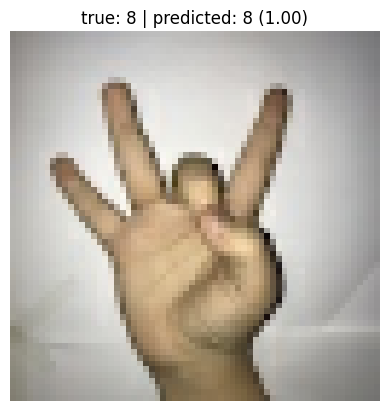

In [37]:
x_batch, y_batch = next(iter(val_ds))
img = x_batch[0]
p = model_c.predict(img[tf.newaxis, ...], verbose=0)[0]   # add the batch dimension

plt.imshow(img.numpy().astype("uint8")); plt.axis("off")
plt.title(f"true: {class_names[np.argmax(y_batch[0])]} | predicted: {class_names[np.argmax(p)]} ({p.max():.2f})")
plt.show()

<a name='4'></a>
## 4 — Sequential vs Functional: summary

| | Sequential API | Functional API |
|---|---|---|
| Model shape | a straight **list** of layers | a **graph** of layers |
| How you write it | `tf.keras.Sequential([layer1, layer2, ...])` | `x = layer(...)(x)`, then `tf.keras.Model(inputs, outputs)` |
| Branches / skip connections | not possible | possible |
| Multiple inputs or outputs | not possible | possible |
| Best for | quick, simple models | anything non-linear (ResNet, Inception, multimodal models) |

| Problem type | Output layer | Loss | Label format |
|---|---|---|---|
| Binary (smile / no smile) | `Dense(1, activation='sigmoid')` | `binary_crossentropy` | 0 or 1 |
| Multiclass (10 digits) | `Dense(10, activation='softmax')` | `categorical_crossentropy` | one-hot |

<a name='5'></a>
## 5 — Reflection questions

Answer briefly in a Markdown cell below.

1. Why does the Dense layer in the smile model have so many more parameters than the Conv2D layer?
2. What would go wrong if you used `softmax` with 1 unit for the smile model? And `sigmoid` with `categorical_crossentropy` for the digits?
3. In your learning curves, is there a gap between training and validation accuracy? What does it mean?
4. What does early stopping do, and why do we set `restore_best_weights=True`?
5. Which digits were confused most often? Suggest **one** change to the data or the model that might fix it.
6. Our smile model could also be written with the Functional API. Write the first three lines of that version.

1. Dense is fully connected (inputs × units + bias), so every pixel/feature connects to every neuron. Conv2D uses small shared kernels, so it has far fewer weights despite large images.

2. Softmax with 1 unit outputs constant 1 → no useful gradient, model can't learn. Sigmoid + categorical_crossentropy is wrong because sigmoid gives independent probabilities, not a 10-class distribution; use softmax + categorical_crossentropy.

3. A gap means overfitting: training accuracy is much higher than validation accuracy, so the model memorizes rather than generalizes.

4. Early stopping stops training when validation performance stops improving. restore_best_weights=True keeps the weights from the best epoch, not the last one.

5. Commonly confused: 4↔9, 3↔5, 6↔9. Fix: use data augmentation (rotations/shifts/zooms) or add more/varied training images.

6. inputs = tf.keras.Input(shape=(64, 64, 3))
x = tfl.Conv2D(8, 4, strides=1, padding="same", activation="relu")(inputs)
x = tfl.MaxPool2D(pool_size=8, strides=8)(x)


<a name='6'></a>
## 6 — References

1. TensorFlow guide — *The Sequential model*: https://www.tensorflow.org/guide/keras/sequential_model
2. TensorFlow guide — *The Functional API*: https://www.tensorflow.org/guide/keras/functional
3. `image_dataset_from_directory`: https://www.tensorflow.org/api_docs/python/tf/keras/utils/image_dataset_from_directory
4. Mavi, A. (2020). *A New Dataset and Proposed Convolutional Neural Network Architecture for Classification of American Sign Language Digits*. arXiv:2011.08927. Dataset: https://github.com/ardamavi/Sign-Language-Digits-Dataset
5. Happy House dataset (originally from the DeepLearning.AI CNN course), Kaggle mirror: https://www.kaggle.com/datasets/iarunava/happy-house-dataset

*Lab adapted and extended by Dr. Naila Marir for CS4085, Effat University.*